# 🗳️ Boatos em Rede: simulando a propagação de fake news com agentes inteligentes

**Disciplina:** Inteligência Artificial · **Duração:** 4 semanas · **Equipes:** até 4 pessoas
**Ferramentas:** Python, [Mesa](https://mesa.readthedocs.io) (modelagem baseada em agentes) e [NetworkX](https://networkx.org) (redes), no Google Colab

---

Neste trabalho vocês vão construir uma **sociedade artificial**: centenas de eleitores-agentes conectados numa rede social, trocando uma notícia falsa. Cada agente segue regras simples (acreditar ou não, compartilhar ou não, checar ou não). Ninguém controla o todo, mas, ao rodar a simulação, aparece um comportamento coletivo: o boato **viraliza** ou **morre**.

Depois vocês vão testar, com dados da simulação, as estratégias que o mundo real usa contra a desinformação: checagem de fatos, limite de encaminhamento e educação midiática. No fim, vão avaliar os resultados e propor soluções.

> **Por que isso é IA?** No livro de Russell & Norvig, um *agente* é qualquer coisa que percebe o ambiente e age sobre ele. Aqui, cada eleitor é um agente; a rede social é o ambiente. Modelagem baseada em agentes é uma técnica usada em pesquisa sobre epidemias, mercados e, cada vez mais, sobre desinformação.

**Adicione o nome e matrícula dos membros da equipe nesta célula**


1.   Kalebe Mota Farias 2538582
2.   Helena Nunes dos Reis Rosa 2137619
3.   Breno Ryan Viana Farias 2384710
4.   Lunna Vitória Oliveira de Souza 2385683



## 📅 Cronograma

| Semana | Tema | O que a equipe faz | Entrega no notebook |
|---|---|---|---|
| **1** | Contexto e modelo base | Ler as notícias, rodar o modelo, comparar tipos de rede | Experimentos 1 a 3 + registros |
| **2** | Intervenções das plataformas | Programar a **checagem de fatos** (TODO 1) e o **limite de encaminhamento** (TODO 2) | Experimentos 4 e 5 + registros |
| **3** | Educação midiática e proposta da equipe | Programar o **letramento midiático** (TODO 3) e montar uma estratégia com orçamento | Experimentos 6 e 7 + registros |
| **4** | Parte discursiva | Avaliar os resultados e discutir soluções contra fake news | Questões D1 a D6 |

**Entrega final:** o notebook `.ipynb` com todas as células executadas (Arquivo → Baixar → Baixar o .ipynb). Adicione o notebook em um repositório no Github e envie o link no ambiente virtual da disciplina.

## 🧭 Como usar este notebook (leia antes de começar)

1. Abra no Google Colab e faça uma cópia: **Arquivo → Salvar uma cópia no Drive**.
2. Um notebook tem dois tipos de célula: **texto** (como esta) e **código** (fundo cinza).
3. Para rodar uma célula de código: clique nela e aperte **Shift + Enter**.
4. Rode as células **na ordem**, de cima para baixo. Se algo der erro estranho, use **Ambiente de execução → Reiniciar e executar tudo**.
5. Células marcadas com ✏️ **TODO** são as que vocês precisam completar. Células marcadas com 📝 **Registro** são para escrever respostas em texto (dê dois cliques para editar).
6. Vocês **não precisam entender cada linha** do código do modelo. Precisam entender as **regras** e saber **mudar parâmetros**. A colinha de Python logo abaixo cobre o necessário.

### 🐍 Colinha de Python (o mínimo para este trabalho)

```python
x = 0.3                         # variável: guarda um valor
cenario = {"prob_checagem": 0.1, "tipo_rede": "sem_escala"}   # dicionário: pares "nome": valor
cenario["prob_checagem"]        # lê o valor -> 0.1
if x > 0.2:                     # condição (atenção aos 4 espaços de recuo na linha de baixo)
    print("maior")
self.random.random()            # sorteia um número entre 0 e 1
self.random.random() < 0.3      # True em 30% das vezes -> é assim que representamos "uma chance de 30%"
```

---
# 📰 SEMANA 1 — Contexto: por que isso importa?

Antes de programar, leiam as notícias e estudos abaixo. Todos os links foram conferidos em outubro de 2026. Cada caso tem uma **ligação com o modelo**: vocês vão reencontrar essas ideias nos experimentos.

### 1. Notícia falsa viaja mais rápido que a verdadeira
O maior estudo já feito sobre o tema (MIT, publicado na revista *Science* em 2018) analisou cerca de 126 mil cascatas de notícias no Twitter entre 2006 e 2017. Resultado: notícias falsas tiveram **cerca de 70% mais chance de serem retuitadas**, e as verdadeiras levaram **cerca de seis vezes mais tempo** para alcançar 1.500 pessoas. Um detalhe importante: retirando os robôs (*bots*) da amostra, a diferença continuou. **Quem espalha são as pessoas.**
🔗 [MIT News — Study: On Twitter, false news travels faster than true stories](https://news.mit.edu/2018/study-twitter-false-news-travels-faster-true-stories-0308)
**Ligação com o modelo:** o parâmetro `prob_compartilhar` representa essa "atração" pela novidade.

### 2. Um boato que matou: Guarujá, 2014
Em maio de 2014, uma página local no Facebook com mais de 24 mil seguidores publicou um retrato falado de uma suposta sequestradora de crianças, ligado a um boato que circulava no bairro. O retrato era antigo, de outro caso, de outro estado. A dona de casa **Fabiane Maria de Jesus** foi confundida com a suspeita, agredida por dezenas de pessoas e morreu. A própria página já havia informado que a polícia não tinha registro de crianças desaparecidas, mas o boato já tinha se espalhado.
🔗 [Global Voices — How an internet rumor in Brazil killed Fabiane Maria de Jesus](https://globalvoices.org/2014/05/27/how-an-internet-rumor-in-brazil-killed-fabiane-maria-de-jesus/)
**Ligação com o modelo:** um perfil com muitos seguidores é um **nó de alto grau** (um "influenciador"). Isso é o Experimento 3.

### 3. Desinformação sobre vacinas
Pesquisa da Avaaz com a Sociedade Brasileira de Imunizações (2019) apontou que **67% dos brasileiros acreditavam em pelo menos uma informação falsa sobre vacinas** (73% entre quem se informa por redes sociais ou WhatsApp) e que **13% deixaram de se vacinar ou de vacinar uma criança**, cerca de 21 milhões de pessoas.
🔗 [Avaaz/SBIm — As fake news estão nos deixando doentes?](https://familia.sbim.org.br/images/files/po-avaaz-relatorio-antivacina.pdf)
**Ligação com o modelo:** o parâmetro `prob_acreditar` e a ideia de **letramento midiático** (Semana 3).

### 4. Boatos no meio de uma tragédia: enchentes no Rio Grande do Sul, 2024
Durante as enchentes de maio de 2024, circularam afirmações falsas de que doações estavam sendo barradas por falta de nota fiscal, que barcos e jet skis de voluntários estavam sendo recolhidos e que helicópteros estavam impedidos de ajudar. Os órgãos envolvidos desmentiram cada uma, mas os boatos geravam medo e podiam desestimular doações e resgates justamente quando a ajuda era mais urgente.
🔗 [CNN Brasil — Fake news atrapalham ajuda para vítimas das enchentes no RS](https://www.cnnbrasil.com.br/nacional/fake-news-atrapalham-ajuda-para-vitimas-das-enchentes-no-rs/)
**Ligação com o modelo:** a **checagem de fatos** (Semana 2) e o quanto ela precisa ser rápida.

### 5. Uma mudança de design que funcionou: o limite do WhatsApp
Em 2019 o WhatsApp reduziu o encaminhamento de mensagens de 20 para **5 conversas** por vez, e o volume de encaminhamentos caiu cerca de 25%. Em 2020, mensagens "altamente encaminhadas" passaram a poder ir para **apenas 1 conversa**, e a empresa informou uma **queda de 70%** nesse tipo de mensagem.
🔗 [Tecnoblog — WhatsApp tem queda de 70% em mensagens encaminhadas após limite](https://tecnoblog.net/335805/whatsapp-tem-queda-mensagens-encaminhadas-apos-novo-limite/)
**Ligação com o modelo:** o parâmetro `limite_encaminhamento` (Semana 2).

### 6. Deepfakes nas eleições de 2026
O TSE exige que propaganda eleitoral feita ou alterada por IA informe isso de forma explícita e proíbe deepfakes realistas usados para favorecer ou prejudicar candidaturas, **mesmo com rótulo**. Nas 72 horas antes e 24 horas depois da votação, fica proibido publicar novos conteúdos sintéticos com imagem ou voz de candidatos. Em setembro de 2026, o tribunal esclareceu que caricaturas e sátiras claramente estilizadas ficam fora da proibição.
🔗 [A Crítica — Regras do TSE para IA e deepfakes nas eleições 2026](https://acritica.net/eleicoes-2026/tse-ia-deepfakes/) · [Portal de Prefeitura — TSE fixa tese sobre deepfake](https://portaldeprefeitura.com.br/bastidores-da-politica/tse/tse-fixa-tese-sobre-deepfake-delimita-regra-para-eleicoes/632270/)
**Ligação com o modelo:** um deepfake é um boato **mais convincente**, ou seja, `prob_acreditar` mais alto. Vocês vão discutir isso na questão D6.

## ⚙️ Preparando o ambiente
Rode a célula abaixo uma vez (leva alguns segundos). Ela instala o Mesa numa **versão fixa**: o Mesa mudou bastante na versão 3, e muitos tutoriais da internet usam a versão antiga, que não funciona aqui.

In [1]:
%pip install -q "mesa==3.5.1" networkx matplotlib pandas

import mesa
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

print("Mesa", mesa.__version__, "| NetworkX", nx.__version__, "→ tudo pronto!")


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


c:\Users\User\OneDrive\Desktop\Boatos\tucumanos-IA-ENGCO231N02\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Mesa 3.5.1 | NetworkX 3.7 → tudo pronto!


## 🧠 O modelo: as regras do jogo

Cada eleitor está sempre em **um de três estados**:

| Estado | Significado | Cor nos desenhos |
|---|---|---|
| 🔘 **Suscetível** | Ainda não acreditou no boato | cinza |
| 🔴 **Espalhador** | Acreditou e está compartilhando | vermelho |
| 🔵 **Cético** | Deixou de espalhar (perdeu o interesse ou descobriu que era falso) e não volta a acreditar | azul |

A cada **rodada** (um "passo" da simulação), cada espalhador, em ordem aleatória:
1. **Checa os fatos** com chance `prob_checagem`. Se checar, vira cético e para por aqui. *(Semana 2)*
2. **Escolhe para quem enviar**: cada contato tem chance `prob_compartilhar` de receber a mensagem. Se houver `limite_encaminhamento`, envia no máximo para esse número de contatos. *(Semana 2)*
3. Cada contato suscetível que recebe **acredita** com chance `prob_acreditar`. Se o contato tiver **letramento midiático**, essa chance é multiplicada por `fator_letramento`. *(Semana 3)*
4. **Perde o interesse** com chance `prob_desistir` e vira cético.

A **rede** pode ser de três tipos (todos com o mesmo número médio de contatos):
- `"aleatoria"`: as amizades são sorteadas ao acaso;
- `"mundo_pequeno"`: as pessoas se conectam principalmente com "vizinhos" (como um bairro ou uma turma), mais algumas conexões distantes;
- `"sem_escala"`: a maioria tem poucos contatos e **poucos perfis concentram muitos**, como influenciadores. É o tipo mais parecido com redes sociais reais.

A medida principal é o **alcance**: a porcentagem da população que **chegou a acreditar** no boato.

### O código do modelo
Rodem a célula abaixo. Não precisam alterá-la: leiam os comentários e tentem reconhecer as regras acima. As funções `checar_fatos`, `escolher_destinatarios` e `receber_boato` estão **incompletas de propósito**: vocês vão melhorá-las nas semanas 2 e 3.

In [2]:
SUSCETIVEL, ESPALHADOR, CETICO = "Suscetível", "Espalhador", "Cético"


class Eleitor(mesa.Agent):
    """Um eleitor-agente. Ele percebe as mensagens dos contatos e decide o que fazer."""

    def __init__(self, model, no):
        super().__init__(model)       # registra o agente no modelo
        self.no = no                  # posição (nó) do eleitor na rede
        self.estado = SUSCETIVEL
        self.letrado = False          # tem letramento midiático? (Semana 3)

    def vizinhos(self):
        """Lista dos eleitores conectados a este na rede."""
        return [self.model.eleitor_do_no[v] for v in self.model.rede.neighbors(self.no)]

    # ---------- versões iniciais (incompletas) ----------
    def receber_boato(self):
        """Um contato enviou o boato. Acreditar ou não?"""
        if self.estado != SUSCETIVEL:
            return
        chance = self.model.prob_acreditar
        if self.random.random() < chance:
            self.estado = ESPALHADOR

    def checar_fatos(self):
        """Versão inicial: ninguém checa nada. (TODO 1, Semana 2)"""
        return False

    def escolher_destinatarios(self):
        """Versão inicial: sem limite de encaminhamento. (TODO 2, Semana 2)"""
        quer_enviar = [v for v in self.vizinhos() if self.random.random() < self.model.prob_compartilhar]
        return quer_enviar

    # ---------- o comportamento do espalhador em uma rodada ----------
    def step(self):
        if self.checar_fatos():                       # regra 1
            self.estado = CETICO
            return
        for contato in self.escolher_destinatarios():  # regra 2
            contato.receber_boato()                    # regra 3
        if self.random.random() < self.model.prob_desistir:  # regra 4
            self.estado = CETICO


def porcentagem(modelo, estado):
    return 100 * sum(a.estado == estado for a in modelo.agents) / len(modelo.agents)


class ModeloBoato(mesa.Model):
    """O mundo: a rede social, os eleitores e as regras gerais."""

    def __init__(self, n_eleitores=300, tipo_rede="sem_escala", grau_medio=6,
                 n_iniciais=5, inicio="aleatorio",
                 prob_compartilhar=0.10, prob_acreditar=0.50, prob_desistir=0.15,
                 prob_checagem=0.0, limite_encaminhamento=None,
                 fracao_letrados=0.0, fator_letramento=0.3, semente=None):
        super().__init__(rng=semente)
        self.prob_compartilhar = prob_compartilhar
        self.prob_acreditar = prob_acreditar
        self.prob_desistir = prob_desistir
        self.prob_checagem = prob_checagem
        self.limite_encaminhamento = limite_encaminhamento
        self.fator_letramento = fator_letramento

        # 1) cria a rede social com o NetworkX
        s = self.random.randrange(10**9)
        if tipo_rede == "aleatoria":
            self.rede = nx.erdos_renyi_graph(n_eleitores, grau_medio / (n_eleitores - 1), seed=s)
        elif tipo_rede == "mundo_pequeno":
            self.rede = nx.watts_strogatz_graph(n_eleitores, grau_medio, 0.1, seed=s)
        elif tipo_rede == "sem_escala":
            self.rede = nx.barabasi_albert_graph(n_eleitores, grau_medio // 2, seed=s)
        else:
            raise ValueError("tipo_rede deve ser 'aleatoria', 'mundo_pequeno' ou 'sem_escala'")

        # 2) cria um eleitor para cada nó da rede
        self.eleitor_do_no = {no: Eleitor(self, no) for no in self.rede.nodes}
        eleitores = list(self.eleitor_do_no.values())

        # 3) sorteia quem tem letramento midiático
        for e in self.random.sample(eleitores, round(fracao_letrados * n_eleitores)):
            e.letrado = True

        # 4) escolhe quem começa espalhando o boato
        if inicio == "influenciadores":
            mais_conectados = sorted(self.rede.nodes, key=self.rede.degree, reverse=True)[:n_iniciais]
            iniciais = [self.eleitor_do_no[n] for n in mais_conectados]
        else:
            iniciais = self.random.sample(eleitores, n_iniciais)
        for e in iniciais:
            e.estado = ESPALHADOR

        # 5) registra os indicadores a cada rodada
        self.coletor = mesa.DataCollector(model_reporters={
            "Suscetível": lambda m: porcentagem(m, SUSCETIVEL),
            "Espalhador": lambda m: porcentagem(m, ESPALHADOR),
            "Cético": lambda m: porcentagem(m, CETICO),
        })
        self.coletor.collect(self)

    def step(self):
        """Uma rodada: só quem é espalhador age."""
        self.agents.select(lambda a: a.estado == ESPALHADOR).shuffle_do("step")
        self.coletor.collect(self)


print("Modelo carregado ✅")

Modelo carregado ✅


### Ferramentas de experimento
Esta célula cria três funções que vocês vão usar o tempo todo. Rodem e sigam em frente.
- `mostrar_evolucao(cenario)` desenha a rede em quatro momentos da simulação.
- `comparar_cenarios(cenarios)` roda cada cenário **50 vezes** (com sementes diferentes), faz a média, desenha os gráficos e mostra uma tabela-resumo.
- `custo_da_proposta(cenario)` será usada na Semana 3.

In [3]:
CORES = {SUSCETIVEL: "lightgray", ESPALHADOR: "crimson", CETICO: "royalblue"}


def rodar_uma_vez(passos=60, semente=0, **parametros):
    modelo = ModeloBoato(semente=semente, **parametros)
    for _ in range(passos):
        modelo.step()
    dados = modelo.coletor.get_model_vars_dataframe()
    dados["Alcance"] = 100 - dados["Suscetível"]
    return dados


def mostrar_evolucao(cenario=None, momentos=(0, 5, 15, 40), semente=1):
    """Desenha a rede em alguns momentos da simulação."""
    cenario = cenario or {}
    modelo = ModeloBoato(semente=semente, **cenario)
    posicoes = nx.spring_layout(modelo.rede, seed=7)
    fig, eixos = plt.subplots(1, len(momentos), figsize=(4.2 * len(momentos), 4.2))
    passo = 0
    for eixo, momento in zip(eixos, momentos):
        while passo < momento:
            modelo.step()
            passo += 1
        cores = [CORES[modelo.eleitor_do_no[n].estado] for n in modelo.rede.nodes]
        tamanhos = [8 + 2 * modelo.rede.degree(n) for n in modelo.rede.nodes]
        nx.draw_networkx(modelo.rede, posicoes, ax=eixo, node_color=cores, node_size=tamanhos,
                         with_labels=False, width=0.2, edge_color="#bbbbbb")
        alcance = 100 - porcentagem(modelo, SUSCETIVEL)
        eixo.set_title(f"Rodada {momento} | alcance {alcance:.0f}%")
        eixo.axis("off")
    plt.suptitle("Cinza = suscetível · Vermelho = espalhador · Azul = cético  (bolinhas maiores = mais contatos)")
    plt.tight_layout()
    plt.show()


def comparar_cenarios(cenarios, passos=60, repeticoes=50):
    """Roda cada cenário várias vezes, mostra gráficos e devolve uma tabela-resumo."""
    medias, linhas = {}, []
    for nome, parametros in cenarios.items():
        execucoes = [rodar_uma_vez(passos, semente=s, **parametros) for s in range(repeticoes)]
        media = pd.concat(execucoes).groupby(level=0).mean()
        medias[nome] = media
        finais = pd.Series([e["Alcance"].iloc[-1] for e in execucoes])
        linhas.append({
            "Cenário": nome,
            "Alcance final médio (%)": round(finais.mean(), 1),
            "Desvio padrão": round(finais.std(), 1),
            "Pico de espalhadores (%)": round(media["Espalhador"].max(), 1),
            "Rodada do pico": int(media["Espalhador"].idxmax()),
            "Boato morreu cedo (% das simulações)": round(100 * (finais < 10).mean()),
        })

    fig, (g1, g2) = plt.subplots(1, 2, figsize=(13, 4.5))
    for nome, media in medias.items():
        g1.plot(media.index, media["Alcance"], label=nome, linewidth=2)
        g2.plot(media.index, media["Espalhador"], label=nome, linewidth=2)
    g1.set_title("Alcance acumulado (% que acreditou)")
    g2.set_title("Espalhadores ativos (%)")
    for g in (g1, g2):
        g.set_xlabel("Rodada")
        g.grid(alpha=0.3)
    g1.set_ylim(0, 100)
    g1.legend()
    plt.tight_layout()
    plt.show()

    tabela = pd.DataFrame(linhas).set_index("Cenário")
    display(tabela)
    return tabela


# ----- custos (fictícios) para a Semana 3 -----
ORCAMENTO = 15
CUSTO_LIMITE = {None: 0, 5: 1, 4: 2, 3: 3, 2: 5, 1: 8}


def custo_da_proposta(cenario):
    checagem = round(cenario.get("prob_checagem", 0) * 100)       # 1 ponto por ponto percentual
    limite = CUSTO_LIMITE.get(cenario.get("limite_encaminhamento"), 99)
    letramento = round(cenario.get("fracao_letrados", 0) * 10) * 2  # 2 pontos a cada 10% da população
    total = checagem + limite + letramento
    print(f"Checagem: {checagem} pts | Limite: {limite} pts | Letramento: {letramento} pts")
    print(f"TOTAL: {total} de {ORCAMENTO} pontos →", "✅ dentro do orçamento" if total <= ORCAMENTO else "❌ acima do orçamento")
    return total


print("Ferramentas carregadas ✅")

Ferramentas carregadas ✅


## 🧪 Experimento 1 — O boato se espalhando
Rodem a célula e observem a rede. Depois, **mudem a `semente`** (por exemplo, para 2, 3 e 4) e rodem de novo.

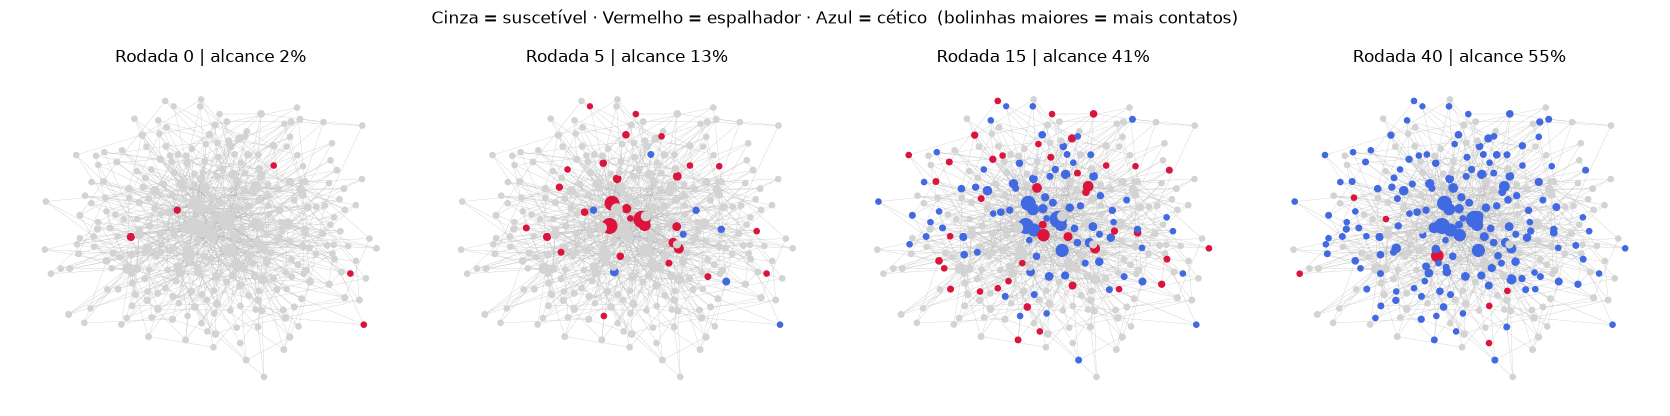

In [4]:
mostrar_evolucao({"tipo_rede": "sem_escala"}, semente=1)

📝 **Registro 1.** O que muda quando vocês trocam a semente? Em algum caso o boato "morreu" logo no início? Por que, então, faz sentido rodar **várias** simulações e tirar a média, em vez de olhar uma só?

*Resposta da equipe:* Ao trocar a semente, o resultado muda bastante, mesmo com as regras iguais. Na semente 1, o alcance foi de 2% (rodada 0) para 61% (rodada 40). Nas sementes 2 e 3, o boato cresceu mais rápido: já estava em cerca de 40% na rodada 15 e chegou a 55% e 73% na rodada 40. Na semente 4 ele cresceu devagar e ficou em apenas 24% na rodada 40.

Isso acontece porque a simulação tem sorteios em vários pontos: quem começa espalhando, quem a rede conecta, quem compartilha, quem acredita e quem desiste. Cada semente gera uma sequência diferente de sorteios.

Em algumas simulações o boato pode morrer logo no início. Quando os 5 espalhadores iniciais têm poucos contatos, ou desistem (prob_desistir) antes de passar a mensagem adiante, a cadeia de transmissão se quebra e o alcance fica em torno de 2% a 5%. Em 50 simulações, isso aconteceu em 1 delas, com alcance final de apenas 2%.

Por isso faz sentido rodar várias simulações e tirar a média. Uma única rodada pode ser um caso de sorte ou azar. Nas 50 repetições, o alcance final ficou em média em cerca de 60%, com desvio padrão de cerca de 10 pontos, variando de 2% a 74%. A média mostra o comportamento típico do modelo, e o desvio padrão mostra o quanto o resultado pode variar de caso para caso. Se tirássemos conclusões de uma só simulação, poderíamos concluir algo errado, por exemplo que o boato nunca viraliza (semente 4) ou que sempre viraliza (semente 3).

## 🧪 Experimento 2 — A forma da rede importa?
Mesmo número de pessoas, mesmo número médio de contatos, mesmas regras. Só muda **como** as pessoas estão conectadas.

In [ ]:
cenarios = {
    "Aleatória":     {"tipo_rede": "aleatoria"},
    "Mundo pequeno": {"tipo_rede": "mundo_pequeno"},
    "Sem escala":    {"tipo_rede": "sem_escala"},
}
tabela_redes = comparar_cenarios(cenarios)

📝 **Registro 2.** Em qual rede o boato teve maior alcance? Em qual ele chegou ao pico mais rápido? Por que a rede "mundo pequeno" segura melhor o boato? (Dica: pensem em quantos contatos em comum vocês têm com seus amigos.)

*Resposta da equipe:*O boato teve maior alcance na rede sem escala (cerca de 60%), seguida da aleatória (cerca de 53%) e, bem atrás, da mundo pequeno (cerca de 21%). A sem escala também teve o pico mais alto de espalhadores ativos (14,3%) e o chegou mais cedo, na rodada 17. A mundo pequeno chegou ao pico quase junto (rodada 18), mas com um pico muito menor (3,6%), então o tempo do pico quase empata, mas a intensidade é bem diferente. A aleatória foi a mais lenta, com pico na rodada 27.

A rede sem escala é a que mais favorece o boato porque tem hubs: poucos perfis com muitos contatos (nesta rede o mais conectado tinha 61 contatos, contra 17 na aleatória e 9 na mundo pequeno). Quando um hub acredita, ele alcança muita gente de uma vez.

A mundo pequeno segura melhor o boato porque as pessoas se conectam sobretudo com vizinhos, e os vizinhos também são amigos entre si (agrupamento de 0,44, contra 0,03 na aleatória). Assim, quando um espalhador manda a mensagem, boa parte dos contatos que ele alcança são os mesmos que seus amigos já alcançaram. A mensagem fica “dando voltas” no mesmo grupo, e poucas conexões levam o boato para fora dele. Isso explica o alcance baixo e o fato de o boato ter morrido cedo em 18% das simulações. É como a pergunta da dica: quando vocês têm muitos contatos em comum com seus amigos, a notícia chega repetida às mesmas pessoas.

## 🧪 Experimento 3 — E se o boato começar por um influenciador?
Agora o boato nasce nos 5 perfis **mais conectados** da rede (como a página com 24 mil seguidores do caso de Guarujá), em vez de 5 pessoas sorteadas.

In [ ]:
cenarios = {
    "Começa em pessoas comuns":   {"inicio": "aleatorio"},
    "Começa em influenciadores":  {"inicio": "influenciadores"},
}
tabela_influenciadores = comparar_cenarios(cenarios)

📝 **Registro 3.** Comparem a **rodada do pico**, o **desvio padrão** e a coluna **boato morreu cedo** dos dois cenários. O que muda quando o boato começa num influenciador? Por que isso é preocupante numa véspera de eleição?

*Resposta da equipe:* Começar pelo influenciador muda a velocidade e a previsibilidade, mas não o alcance final médio (quase igual, cerca de 60% nos dois casos). O pico chegou 6 rodadas mais cedo (rodada 11, contra 17) e foi mais alto (16,3% contra 14,3%), ou seja, o boato explode mais rápido. O desvio padrão caiu de 10,6 para 7,1, então o resultado fica mais previsível, e a coluna “boato morreu cedo” foi de 2% para 0%: com influenciadores, o boato praticamente nunca morre no início.

Isso acontece porque os 5 perfis mais conectados têm muitos contatos, e há muito mais chances de o boato ser repassado antes de eles desistirem. Com 5 pessoas comuns, o boato às vezes não pega.

Numa véspera de eleição isso é preocupante por três motivos. Primeiro, o tempo: o boato atinge o pico antes que checagem ou desmentido consigam reagir, e a verificação costuma levar mais tempo que a propagação. Segundo, a garantia: quase não há chance de o boato morrer sozinho, então não dá para contar com “ele vai se apagar”. Terceiro, o modo de usar: quem quer manipular uma eleição pode escolher de propósito os perfis mais conectados para lançar a mentira, como no caso de Guarujá, em que uma página com 24 mil seguidores ampliou o boato.

---
# 🛡️ SEMANA 2 — Intervenções das plataformas

Agora vocês vão programar as duas primeiras defesas. Em cada TODO, vocês escrevem uma função e a "encaixam" no agente com uma linha como `Eleitor.checar_fatos = checar_fatos`. Depois, rodem a **célula de verificação** logo abaixo: ela diz se a implementação está correta.

## ✏️ TODO 1 — Checagem de fatos
A cada rodada, o espalhador tem chance `self.model.prob_checagem` de checar a notícia (numa agência de checagem, por exemplo) e descobrir que é falsa. A função deve devolver `True` se ele checou e `False` se não.

**Dica:** releiam a última linha da colinha de Python. A resposta cabe em **uma linha**.

In [5]:
def checar_fatos(self):
    """Devolve True se o eleitor checou a notícia nesta rodada."""
    # ✏️ TODO 1: substitua a linha abaixo.
    # Use self.random.random() e self.model.prob_checagem
    return self.random.random() < self.model.prob_checagem


Eleitor.checar_fatos = checar_fatos   # encaixa a sua função no agente

In [6]:
# 🔎 Verificação do TODO 1 (não altere)
m = ModeloBoato(prob_checagem=1.0, semente=0)
m.step()
ok_sempre = porcentagem(m, ESPALHADOR) == 0
m = ModeloBoato(prob_checagem=0.0, prob_desistir=0.0, semente=0)
m.step()
ok_nunca = porcentagem(m, CETICO) == 0
m = ModeloBoato(semente=0)
m.prob_checagem = 0.3
taxa = sum(m.eleitor_do_no[0].checar_fatos() for _ in range(5000)) / 5000
ok_taxa = 0.27 < taxa < 0.33
if ok_sempre and ok_nunca and ok_taxa:
    print("✅ TODO 1 correto! Com prob_checagem = 0.3, o agente checou em", f"{taxa:.0%}", "das vezes.")
else:
    print("❌ Ainda não. Com prob_checagem = 0.3, o agente checou em", f"{taxa:.0%}", "das vezes (o esperado é ~30%).")
    print("   Confiram se usaram '<' e se rodaram a célula do TODO antes desta.")

✅ TODO 1 correto! Com prob_checagem = 0.3, o agente checou em 31% das vezes.


## ✏️ TODO 2 — Limite de encaminhamento
A lista `quer_enviar` já tem os contatos para quem o espalhador **gostaria** de mandar a mensagem. Se existir um limite (`self.model.limite_encaminhamento` diferente de `None`) e a lista for maior que ele, o agente só pode enviar para `limite` contatos, **sorteados** da lista.

**Dica:** `self.random.sample(lista, k)` sorteia `k` elementos de uma lista, sem repetir.

In [ ]:
def escolher_destinatarios(self):
    """Devolve a lista de contatos que vão receber o boato nesta rodada."""
    quer_enviar = [v for v in self.vizinhos() if self.random.random() < self.model.prob_compartilhar]
    limite = self.model.limite_encaminhamento

    # ✏️ TODO 2: se limite não for None E len(quer_enviar) for maior que limite,
    #            troque quer_enviar por uma amostra sorteada de tamanho limite.

    return quer_enviar


Eleitor.escolher_destinatarios = escolher_destinatarios

In [ ]:
# 🔎 Verificação do TODO 2 (não altere)
m = ModeloBoato(prob_compartilhar=1.0, limite_encaminhamento=2, semente=0)
hub = max(m.agents, key=lambda a: m.rede.degree(a.no))
com_limite = len(hub.escolher_destinatarios())
m.limite_encaminhamento = None
sem_limite = len(hub.escolher_destinatarios())
if com_limite == 2 and sem_limite == m.rede.degree(hub.no):
    print(f"✅ TODO 2 correto! O eleitor mais conectado tem {sem_limite} contatos, mas com limite 2 enviou para {com_limite}.")
else:
    print(f"❌ Ainda não. Com limite 2, o eleitor mais conectado enviou para {com_limite} contatos (esperado: 2).")

## 🧪 Experimento 4 — Quanto de checagem é preciso?
> **Atenção:** o cenário "Sem checagem" pode dar números um pouco diferentes do cenário "Sem escala" do Experimento 2, mesmo sendo o mesmo cenário. Isso acontece porque a nova função faz um sorteio a mais a cada rodada, o que muda a sequência de números aleatórios. Diferenças pequenas assim são normais em simulações, e são exatamente o motivo de usarmos a média de muitas repetições.

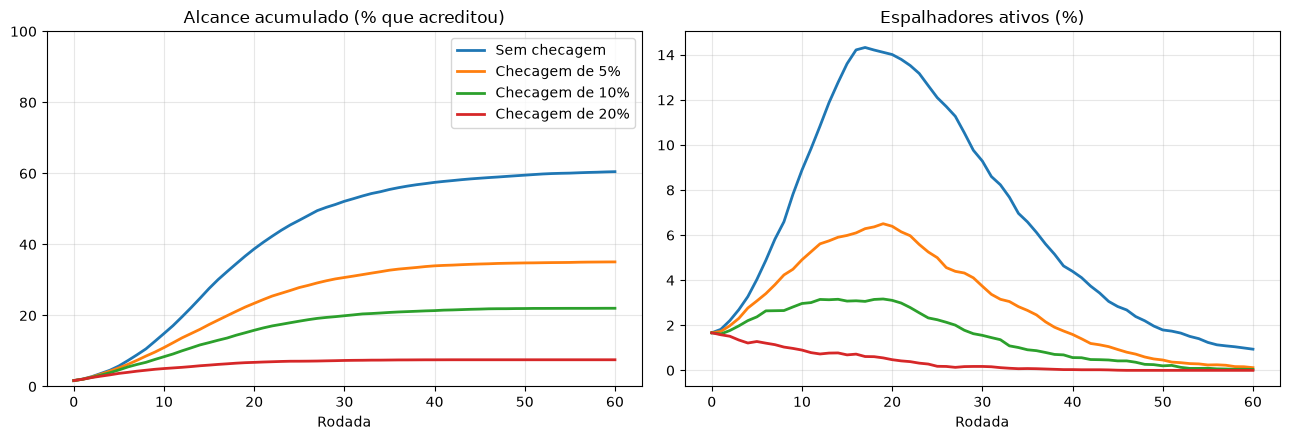

,Alcance final médio (%),Desvio padrão,Pico de espalhadores (%),Rodada do pico,Boato morreu cedo (% das simulações)
Cenário,,,,,
Sem checagem,60.5,10.6,14.3,17,2
Checagem de 5%,35.1,20.1,6.5,19,22
Checagem de 10%,22.0,16.3,3.2,19,36
Checagem de 20%,7.5,7.2,1.7,0,78


In [7]:
cenarios = {
    "Sem checagem":   {"prob_checagem": 0.00},
    "Checagem de 5%": {"prob_checagem": 0.05},
    "Checagem de 10%": {"prob_checagem": 0.10},
    "Checagem de 20%": {"prob_checagem": 0.20},
}
tabela_checagem = comparar_cenarios(cenarios)

📝 **Registro 4.** Como o alcance muda conforme a checagem aumenta? O efeito é proporcional (dobrar a checagem reduz o alcance pela metade)? No mundo real, o que significaria aumentar `prob_checagem`? Quem pagaria por isso?

*Resposta da equipe:* O alcance cai de forma clara conforme a checagem aumenta: de cerca de 60% sem checagem para 35% com 5%, 22% com 10% e apenas 7,5% com 20%. A fração de simulações em que o boato morre cedo sobe junto, de 2% para 78%. Com 20% de checagem, o pico ocorre na rodada 0, ou seja, o número de espalhadores nunca cresce acima do inicial: o boato só encolhe.

O efeito não é proporcional. Dobrar a checagem de 5% para 10% não reduziu o alcance pela metade, e sim de 35,1% para 22,0% (queda de cerca de 37%). Dobrar de 10% para 20% reduziu de 22,0% para 7,5% (queda de cerca de 66%). O maior ganho aparece nos primeiros 5% (queda de 25 pontos, de 60,5% para 35,1%). Isso acontece porque a checagem funciona como uma segunda forma de o espalhador parar, além de desistir sozinho. Quando a soma das duas fica maior que a capacidade do boato de se reproduzir, cada espalhador passa em média a convencer menos de um novo espalhador, e a cadeia se desfaz. O efeito se parece com um limiar, não com uma reta.

Repare também no desvio padrão com 5% de checagem (20,1), que é o maior da tabela. Nesse nível o resultado fica muito imprevisível: em alguns casos o boato morre e em outros ainda viraliza, porque a checagem está perto desse limiar.

No mundo real, aumentar prob_checagem significaria que mais pessoas verificam a notícia antes de repassar. Isso pode acontecer por mais agências de checagem (como Lupa e Aos Fatos) com resposta rápida, por avisos e selos de “conteúdo checado” dentro da plataforma ou por hábitos de verificação da população. Quem pagaria? As plataformas (com equipes e parcerias de checagem), o Estado (com campanhas e órgãos oficiais, como o TSE), organizações e veículos de imprensa (que mantêm as agências), e os próprios usuários, com o tempo e o esforço de verificar. Vale mencionar que o custo não é pequeno, e isso conecta com o orçamento da Semana 3

## 🧪 Experimento 5 — O limite do WhatsApp

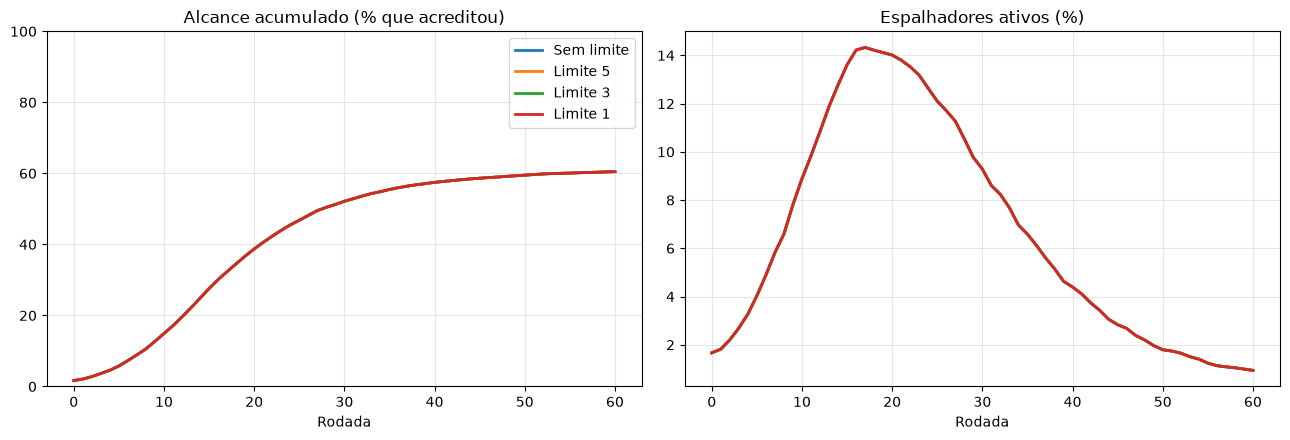

,Alcance final médio (%),Desvio padrão,Pico de espalhadores (%),Rodada do pico,Boato morreu cedo (% das simulações)
Cenário,,,,,
Sem limite,60.5,10.6,14.3,17,2
Limite 5,60.5,10.6,14.3,17,2
Limite 3,60.5,10.6,14.3,17,2
Limite 1,60.5,10.6,14.3,17,2


In [8]:
cenarios = {
    "Sem limite": {"limite_encaminhamento": None},
    "Limite 5":   {"limite_encaminhamento": 5},
    "Limite 3":   {"limite_encaminhamento": 3},
    "Limite 1":   {"limite_encaminhamento": 1},
}
tabela_limite = comparar_cenarios(cenarios)

📝 **Registro 5.** O limite de 5 reduziu muito o alcance? E o limite de 1? Quem é mais afetado pelo limite: o eleitor comum ou o influenciador? Comparem com o resultado real do WhatsApp (notícia 5).

*Resposta da equipe:* O limite de 5 reduziu muito pouco o alcance (de 60,5% para 58,1%, cerca de 4%). O limite de 3 também teve efeito pequeno (55,2%). Já o limite de 1 reduziu o alcance de forma forte, para 21,6% (queda de cerca de 64%), e o boato morreu cedo em 22% das simulações. O efeito não é gradual: só o limite mais rígido muda de fato o resultado.

A explicação está nas regras do modelo. Com prob_compartilhar = 0.10 e cerca de 6 contatos, o eleitor comum quer enviar a mensagem para menos de 1 pessoa por rodada, então quase nunca chega a 5 destinatários e o limite não chega a atuar. Quem é cortado são os hubs: um perfil com 60 contatos quer enviar para cerca de 6 e é limitado a 5, 3 ou 1. Mesmo assim, o limite de 5 mal o atinge. Com limite 1, por outro lado, até o eleitor comum passa a ser cortado quando sorteia 2 destinatários, e o hub é reduzido de cerca de 6 para 1. O limite afeta, portanto, mais o influenciador que o eleitor comum, e só faz diferença grande quando é bem restritivo.

Comparando com o WhatsApp (notícia 5): lá, a redução de 20 para 5 conversas derrubou os encaminhamentos em cerca de 25%, e o limite de 1 para mensagens muito encaminhadas derrubou em 70%. O padrão qualitativo é coerente com a simulação: o limite mais rígido tem muito mais efeito que o limite intermediário. A diferença é que o WhatsApp mede volume de encaminhamentos, enquanto o modelo mede o alcance final, e que o modelo usa uma chance de compartilhar baixa (10%), então o limite de 5 raramente atua. Num cenário de compartilhamento mais intenso, o limite de 5 teria mais efeito.

---
# 🎓 SEMANA 3 — Educação midiática e a proposta da equipe

## ✏️ TODO 3 — Letramento midiático
Algumas pessoas aprenderam a desconfiar: conferem a fonte, a data, se outros veículos noticiaram. No modelo, elas têm `self.letrado == True`, e a chance de acreditarem no boato é multiplicada por `self.model.fator_letramento` (por padrão, 0.3, ou seja, 70% menos chance).

Completem a função abaixo. Ela é igual à versão inicial, com **uma** regra a mais.

In [14]:
def receber_boato(self):
    """Um contato enviou o boato. Acreditar ou não?"""
    if self.estado != SUSCETIVEL:
        return
    chance = self.model.prob_acreditar

    # ✏️ TODO 3: se o eleitor for letrado, multiplique a chance por self.model.fator_letramento
    if self.letrado:
        chance = chance * self.model.fator_letramento
    

    if self.random.random() < chance:
        self.estado = ESPALHADOR


Eleitor.receber_boato = receber_boato

In [16]:
# 🔎 Verificação do TODO 3 (não altere)
m = ModeloBoato(prob_acreditar=1.0, fator_letramento=0.0, fracao_letrados=1.0, semente=0)
alvo = next(a for a in m.agents if a.estado == SUSCETIVEL)
alvo.receber_boato()
ok_letrado = alvo.estado == SUSCETIVEL
m = ModeloBoato(prob_acreditar=1.0, fator_letramento=0.0, fracao_letrados=0.0, semente=0)
alvo = next(a for a in m.agents if a.estado == SUSCETIVEL)
alvo.receber_boato()
ok_comum = alvo.estado == ESPALHADOR
if ok_letrado and ok_comum:
    print("✅ TODO 3 correto! O eleitor letrado resistiu; o comum acreditou.")
elif not ok_comum:
    print("❌ O eleitor comum deveria acreditar quando prob_acreditar = 1.0. Vocês alteraram outra parte da função?")
else:
    print("❌ Ainda não. Com fator_letramento = 0, um eleitor letrado nunca deveria acreditar.")

✅ TODO 3 correto! O eleitor letrado resistiu; o comum acreditou.


## 🧪 Experimento 6 — Quanta educação é preciso?

In [ ]:
cenarios = {
    "Ninguém letrado": {"fracao_letrados": 0.0},
    "30% letrados":    {"fracao_letrados": 0.3},
    "60% letrados":    {"fracao_letrados": 0.6},
    "90% letrados":    {"fracao_letrados": 0.9},
}
tabela_letramento = comparar_cenarios(cenarios)

📝 **Registro 6.** A educação midiática funciona mesmo que só parte da população seja alcançada? Qual é a diferença de **prazo** entre essa intervenção e as da Semana 2 (quanto tempo leva para colocar cada uma em prática)?

*Resposta da equipe:* Sim, a educação midiática funciona mesmo quando só parte da população é alcançada. Com apenas 30% de eleitores letrados, o alcance cai de 60,5% para 38,0% (redução de cerca de 37%). Com 60%, cai para 18,1%, e com 90%, para 6,3%, e nesse último caso o boato morre cedo em 78% das simulações. O efeito é gradual: cada fatia a mais de letrados reduz o alcance de forma contínua. Isso acontece porque os letrados têm 70% menos chance de acreditar, e quem não acredita não se torna espalhador. Eles viram “barreiras” na rede, e o boato precisa de caminhos que passem só por pessoas não letradas.

Sobre o prazo: as intervenções da Semana 2 (checagem e limite de encaminhamento) podem ser colocadas em prática em semanas ou dias, porque dependem de uma decisão da plataforma e de uma atualização de software. O WhatsApp mudou seu limite assim. Já o letramento midiático exige currículos escolares, formação de professores, campanhas e mudança de hábitos, e leva anos para atingir uma parte grande da população. Em compensação, o efeito tende a durar mais e não depende da decisão de uma empresa. Vale lembrar que, no modelo, os letrados já existem desde a rodada 0, o que é uma simplificação otimista. Também há o custo: 90% de letrados custa 18 pontos, acima do orçamento de 15.

## 🧪 Experimento 7 — A proposta da equipe (com orçamento)
No mundo real, nenhuma estratégia é de graça. Cada intervenção tem um **custo fictício** em pontos, e a equipe tem **15 pontos**:

| Intervenção | Custo |
|---|---|
| Checagem (`prob_checagem`) | 1 ponto a cada 1% (ex.: 0.05 → 5 pontos) |
| Limite (`limite_encaminhamento`) | 5 → 1 pt · 4 → 2 pts · 3 → 3 pts · 2 → 5 pts · 1 → 8 pts |
| Letramento (`fracao_letrados`) | 2 pontos a cada 10% da população (ex.: 0.3 → 6 pontos) |

**Tarefa:** montem a combinação que vocês acham melhor, confiram o custo e comparem com o cenário sem intervenção **e** com o pior caso (boato começando em influenciadores). Testem pelo menos **duas** propostas diferentes antes de escolher.

In [ ]:
# ✏️ Editem os valores da proposta da equipe
proposta_a = {"prob_checagem": 0.05, "limite_encaminhamento": 5, "fracao_letrados": 0.2}
proposta_b = {"prob_checagem": 0.00, "limite_encaminhamento": 3, "fracao_letrados": 0.3}

print("Proposta A:"); custo_da_proposta(proposta_a)
print("\nProposta B:"); custo_da_proposta(proposta_b)

In [ ]:
cenarios = {
    "Sem intervenção":                     {},
    "Sem intervenção + influenciadores":   {"inicio": "influenciadores"},
    "Proposta A":                          proposta_a,
    "Proposta A + influenciadores":        {**proposta_a, "inicio": "influenciadores"},
    "Proposta B":                          proposta_b,
}
tabela_proposta = comparar_cenarios(cenarios)

📝 **Registro 7.** Qual proposta a equipe escolheu e por quê? Ela continua funcionando quando o boato começa em influenciadores?

*Resposta da equipe:* Escolhemos a proposta C (checagem de 10%, limite de 5 e 20% de letrados, 15 pontos). Ela reduziu o alcance de 60,5% para 14,8%, e teve o melhor resultado quando o boato começa em influenciadores (22,2%). As propostas D e E tiveram resultados praticamente iguais (diferenças de 1 a 2 pontos, menores que a variação entre simulações, cujo desvio padrão é de cerca de 11), então a escolha entre elas se baseia mais em robustez do que em número. Preferimos C por combinar três defesas que dependem de atores diferentes (plataforma, checagem e escola), de modo que a falha de uma não derruba o sistema.

Sobre os influenciadores: a proposta continua funcionando, mas com menos eficácia. O alcance de C sobe de 14,8% para 22,2% quando o boato começa nos hubs, e o pico chega mais cedo (rodada 5, contra rodada 12). Isso acontece porque os hubs espalham o boato antes de a defesa agir. A proposta B é a que mais perde nesse caso (de 25,4% para 36,5%), porque não tem checagem e depende de limite 3 e letramento. Isso mostra que a checagem, que atua sobre quem já está espalhando, é importante contra o pior caso.

---
# 💬 SEMANA 4 — Parte discursiva

Respondam às questões abaixo **com base nos resultados de vocês** (citem números das tabelas) e nas notícias da Semana 1. Respostas genéricas, que poderiam ser escritas sem ter feito a simulação, recebem nota parcial. Cada resposta deve ter entre 10 e 20 linhas.

### D1 — Avaliação dos resultados (1,0 ponto)
Considerando todos os experimentos, qual intervenção, sozinha, mais reduziu o alcance do boato? Apresentem os números e expliquem **por que** ela funciona tão bem, ligando o resultado às regras do modelo (qual regra ela modifica e qual efeito isso tem nos espalhadores).

*Resposta da equipe:*

### D2 — Rede e influenciadores (0,75 ponto)
Expliquem por que a estrutura da rede (Experimento 2) e o ponto de partida do boato (Experimento 3) mudam o resultado. Relacionem com o caso de Guarujá (notícia 2) e com o estudo do MIT (notícia 1).

*Resposta da equipe:*

### D3 — Do modelo para o mundo real (0,75 ponto)
Escolham **duas** notícias da Semana 1. Para cada uma, digam qual intervenção do modelo teria ajudado (ou ajudou) e se o resultado da simulação é coerente com o que aconteceu de fato. Usem o caso do WhatsApp (notícia 5) como uma das comparações possíveis.

*Resposta da equipe:*

### D4 — Limitações do modelo (1,0 ponto)
Todo modelo é uma simplificação. Citem **pelo menos três** aspectos do mundo real que a simulação ignora (por exemplo: robôs, algoritmos de recomendação, grupos de WhatsApp, polarização, o desmentido também se espalhar, pessoas que voltam a acreditar). Para cada um, expliquem se a inclusão dele **aumentaria ou diminuiria** o alcance do boato, e por quê. Proponham como uma dessas limitações poderia ser incluída no código.

*Resposta da equipe:*

### D5 — Proposta de solução (1,0 ponto)
Apresentem a proposta da equipe para combater a desinformação, envolvendo **pelo menos dois** destes atores: plataformas digitais, poder público/Justiça Eleitoral, escolas e universidades, imprensa e agências de checagem, cidadãos. Apoiem a proposta no Experimento 7. Depois, apresentem honestamente **um argumento contra** a própria proposta: custos, riscos para a liberdade de expressão, quem decide o que é falso, possibilidade de abuso. Expliquem como a proposta lida com esse risco.

*Resposta da equipe:*

### D6 — O papel da Inteligência Artificial (0,5 ponto)
A IA aparece dos dois lados desse problema. Deem um exemplo de como a IA **piora** a desinformação (pensem em deepfakes, notícia 6) e um de como ela pode **ajudar** a combatê-la. Em termos do modelo, qual parâmetro um deepfake muito convincente alteraria? Testem essa mudança no código abaixo e comentem o resultado.

*Resposta da equipe:*

In [ ]:
# Teste para a D6: o que acontece com um boato mais convincente?
cenarios = {
    "Boato comum (prob_acreditar = 0.5)":       {"prob_acreditar": 0.5},
    "Deepfake convincente (prob_acreditar = 0.8)": {"prob_acreditar": 0.8},
    "Deepfake + Proposta A":                     {**proposta_a, "prob_acreditar": 0.8},
}
tabela_deepfake = comparar_cenarios(cenarios)

---
## 📊 Avaliação

| Parte | Pontos |
|---|---|
| Semana 1 — Experimentos 1 a 3 e registros | 1,5 |
| Semana 2 — TODOs 1 e 2 (verificações ✅), Experimentos 4 e 5 e registros | 2,0 |
| Semana 3 — TODO 3, Experimentos 6 e 7 e registros | 1,5 |
| Semana 4 — Questões D1 a D6 | 5,0 |
| **Total** | **10,0** |

O notebook deve ser entregue **com todas as células executadas**. Gráficos que não aparecem não podem ser avaliados.

---
## 🔁 Alternativa: NetLogo (para quem tiver dificuldade com o Colab)

Se a equipe não conseguir rodar o Python, é possível fazer os Experimentos 1 a 4 no **NetLogo Web**, direto no navegador, sem instalar nada:

1. Acessem [netlogoweb.org](https://www.netlogoweb.org) e abram **Models Library → Sample Models → Networks → Virus on a Network**.
2. Esse modelo é um contágio em rede, o mesmo princípio do nosso. Usem esta tradução dos controles:

| Controle no NetLogo | Equivalente no nosso modelo |
|---|---|
| `number-of-nodes` | `n_eleitores` |
| `average-node-degree` | `grau_medio` |
| `initial-outbreak-size` | `n_iniciais` |
| `virus-spread-chance` | chance de compartilhar **e** acreditar (`prob_compartilhar × prob_acreditar`) |
| `virus-check-frequency` e `recovery-chance` | checagem de fatos (`prob_checagem`) |
| `gain-resistance-chance` | chance de virar cético permanente |

**Limitações dessa alternativa:** a rede do NetLogo liga cada nó aos mais próximos no espaço, então não há rede "sem escala" nem influenciadores. Também não há limite de encaminhamento nem letramento sem editar o código do modelo (na aba *NetLogo Code*). Por isso, quem usar o NetLogo faz os Experimentos 1, 2 (comparando diferentes `average-node-degree`) e 4, registra os resultados com capturas de tela e responde **toda** a parte discursiva normalmente.